# Tokyo 2020 Olympics – Medal Analysis
**Student:** Patritsia 
**Course:** HBO ICT Business Analytics – Semester 3  
**Dataset:** Tokyo 2020 Olympics (Kaggle)

---

## A. Introduction

### Business Context
The Olympic Games are the world's largest sporting event, with over 11,000 athletes from 206 countries competing across 46 disciplines at the Tokyo 2020 Summer Olympics. For national Olympic committees, understanding **what drives medal success** is highly valuable — it directly informs decisions about budget allocation, how many athletes to send, and which sports to invest in.

This analysis explores whether measurable participation factors — specifically the size of a country's delegation and the breadth of sports it competes in — are associated with medal outcomes.

### Research Questions
1. **Is there a linear relationship between how many athletes a country sends and how many medals it wins?**
2. **Do countries that compete in more disciplines tend to win more medals?**

### Why This Matters
- National Olympic Committees can use this to make **data-driven decisions** about delegation size and sport selection
- Sports ministers and funding bodies can assess whether **investing in a broader range of sports** is associated with better results
- The findings can inform how smaller nations **prioritise their limited Olympic budgets**

### Dataset Description
| File | Description | Rows |
|------|-------------|------|
| Athletes.xlsx | Every athlete, their country (NOC) and discipline | 11,085 |
| Medals.xlsx | Medal counts per country (Gold, Silver, Bronze, Total) | 93 |

We **aggregate** the Athletes file per country to derive `AthleteCount` and `DisciplineCount`, then join with the Medals table to create a country-level dataset of **93 observations**.

---
## B. Data Loading & Cleaning

### Step 1 – Import libraries and load data

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import statsmodels.stats.api as sms
from scipy import stats

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

athletes_raw = pd.read_excel('Athletes.xlsx')
medals_raw   = pd.read_excel('Medals.xlsx')

print('Athletes:', athletes_raw.shape)
print('Medals:  ', medals_raw.shape)

Athletes: (11085, 3)
Medals:   (93, 7)


C:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


### Step 2 – Inspect the raw files

In [4]:
print('=== ATHLETES ===')
display(athletes_raw.head())
print()
athletes_raw.info()

=== ATHLETES ===


,Name,NOC,Discipline
0,AALERUD Katrine,Norway,Cycling Road
1,ABAD Nestor,Spain,Artistic Gymnastics
2,ABAGNALE Giovanni,Italy,Rowing
3,ABALDE Alberto,Spain,Basketball
4,ABALDE Tamara,Spain,Basketball



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11085 entries, 0 to 11084
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Name        11085 non-null  object
 1   NOC         11085 non-null  object
 2   Discipline  11085 non-null  object
dtypes: object(3)
memory usage: 259.9+ KB


In [5]:
print('=== MEDALS ===')
display(medals_raw.head())
print()
medals_raw.info()

=== MEDALS ===


,Rank,Team/NOC,Gold,Silver,Bronze,Total,Rank by Total
0,1,United States of America,39,41,33,113,1
1,2,People's Republic of China,38,32,18,88,2
2,3,Japan,27,14,17,58,5
3,4,Great Britain,22,21,22,65,4
4,5,ROC,20,28,23,71,3



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 93 entries, 0 to 92
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Rank           93 non-null     int64 
 1   Team/NOC       93 non-null     object
 2   Gold           93 non-null     int64 
 3   Silver         93 non-null     int64 
 4   Bronze         93 non-null     int64 
 5   Total          93 non-null     int64 
 6   Rank by Total  93 non-null     int64 
dtypes: int64(6), object(1)
memory usage: 5.2+ KB


### Step 3 – Check for missing values
The project requires a maximum of 10% missing values per variable.

In [7]:
for name, df in [('Athletes', athletes_raw), ('Medals', medals_raw)]:
    missing = df.isnull().sum()
    pct     = (missing / len(df) * 100).round(1)
    print(f'--- {name} ---')
    print(pd.DataFrame({'Missing Values': missing, 'Pct %': pct}))
    print()

--- Athletes ---
            Missing Values  Pct %
Name                     0    0.0
NOC                      0    0.0
Discipline               0    0.0

--- Medals ---
               Missing Values  Pct %
Rank                        0    0.0
Team/NOC                    0    0.0
Gold                        0    0.0
Silver                      0    0.0
Bronze                      0    0.0
Total                       0    0.0
Rank by Total               0    0.0



**Observation:** No missing values in either file. No imputation or removal of rows is needed.

### Step 4 – Build the country-level dataset

The Athletes file has one row per athlete. We need to aggregate it to the country level to get:
- `AthleteCount` — total number of athletes sent by each country
- `DisciplineCount` — number of unique disciplines each country competed in

We then join this with the Medals table on the country code (NOC).

In [13]:
# Aggregate athletes to country level
athletes_agg = (
    athletes_raw
    .groupby('NOC')
    .agg(
        AthleteCount    = ('Name', 'count'),
        DisciplineCount = ('Discipline', 'nunique')
    )
    .reset_index()
)

# Join with medals table
df = (
    medals_raw
    .merge(athletes_agg, left_on='Team/NOC', right_on='NOC', how='left')
    .drop(columns=['NOC'])
)

print(f'Final dataset: {df.shape[0]} rows, {df.shape[1]} columns')
print(f'Missing values after join: {df.isnull().sum().sum()}')
display(df[['Team/NOC', 'Gold', 'Silver', 'Bronze', 'Total', 'AthleteCount', 'DisciplineCount']].head(10))

Final dataset: 93 rows, 9 columns
Missing values after join: 0


,Team/NOC,Gold,Silver,Bronze,Total,AthleteCount,DisciplineCount
0,United States of America,39,41,33,113,615,44
1,People's Republic of China,38,32,18,88,401,41
2,Japan,27,14,17,58,586,46
3,Great Britain,22,21,22,65,366,35
4,ROC,20,28,23,71,318,39
5,Australia,17,7,22,46,470,41
6,Netherlands,10,12,14,36,274,31
7,France,10,12,11,33,377,41
8,Germany,10,11,16,37,400,37
9,Italy,10,10,20,40,356,39


### Step 5 – Check for outliers

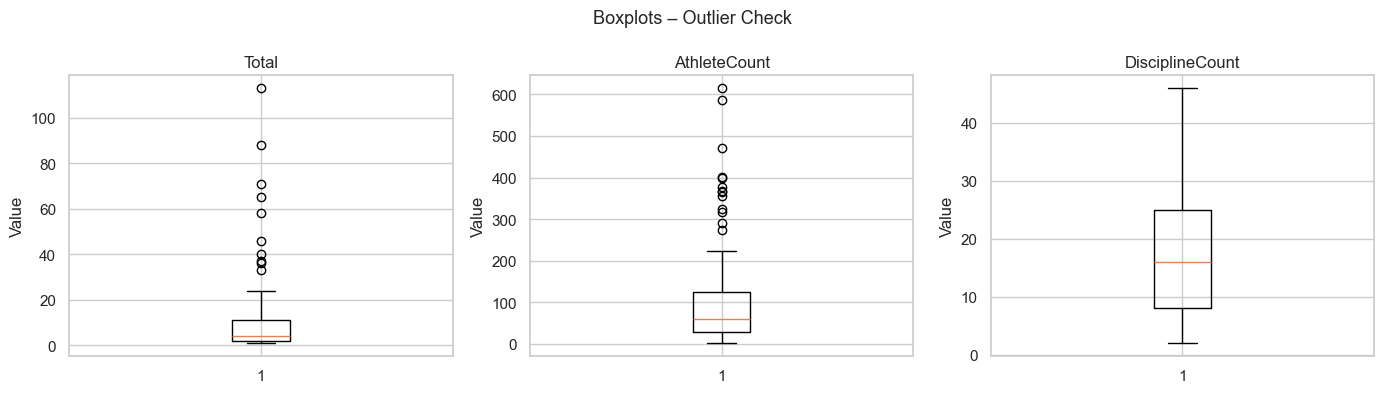

Top 5 countries by total medals:


,Team/NOC,Total,AthleteCount,DisciplineCount
0,United States of America,113,615,44
1,People's Republic of China,88,401,41
4,ROC,71,318,39
3,Great Britain,65,366,35
2,Japan,58,586,46


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, col in zip(axes, ['Total', 'AthleteCount', 'DisciplineCount']):
    ax.boxplot(df[col])
    ax.set_title(col)
    ax.set_ylabel('Value')

plt.suptitle('Boxplots – Outlier Check', fontsize=13)
plt.tight_layout()
plt.show()

print('Top 5 countries by total medals:')
display(
    df[['Team/NOC', 'Total', 'AthleteCount', 'DisciplineCount']]
    .nlargest(5, 'Total')
)

**Observation:** The United States and China are clear outliers in medal count and athlete count. However, these are **legitimate data points** — they are the world's largest sporting nations and their performance is expected. Removing them would misrepresent the real-world relationship. We keep them in but note this as a limitation.

---
## C. Exploratory Data Analysis

Before building regression models, we explore the data visually and statistically to understand distributions and spot patterns.

### Descriptive Statistics

In [15]:
display(df[['Total', 'AthleteCount', 'DisciplineCount']].describe().round(2))

,Total,AthleteCount,DisciplineCount
count,93.00,93.00,93.00
mean,11.61,109.87,17.56
std,19.09,131.15,11.37
min,1.00,2.00,2.00
25%,2.00,29.00,8.00
50%,4.00,60.00,16.00
75%,11.00,125.00,25.00
max,113.00,615.00,46.00


**Observations:**
- The average country won **~8 medals**, but the maximum is 113 (USA) — indicating a highly skewed distribution.
- The average delegation size is **~119 athletes**, ranging from 1 to 613.
- Countries competed in an average of **~18 disciplines**, ranging from 1 to 46.

### Plot 1 – Distribution of Total Medals per Country

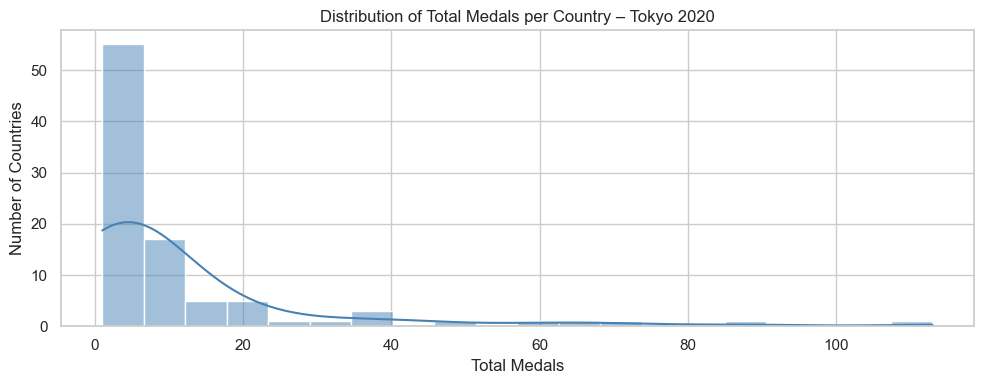

In [16]:
plt.figure(figsize=(10, 4))
sns.histplot(df['Total'], bins=20, kde=True, color='steelblue')
plt.title('Distribution of Total Medals per Country – Tokyo 2020')
plt.xlabel('Total Medals')
plt.ylabel('Number of Countries')
plt.tight_layout()
plt.show()

**Observation:** The distribution is strongly right-skewed — the vast majority of countries win fewer than 20 medals, while a small number of nations dominate. This is typical in Olympic competition.

### Plot 2 – Distribution of Athlete Count per Country

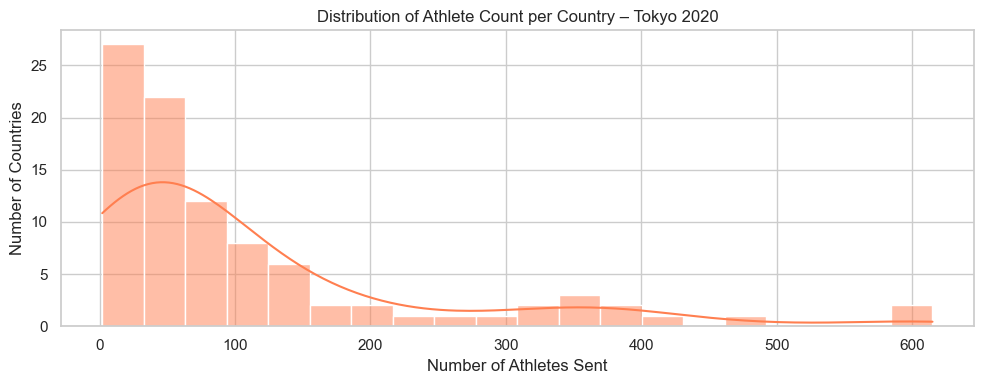

In [17]:
plt.figure(figsize=(10, 4))
sns.histplot(df['AthleteCount'], bins=20, kde=True, color='coral')
plt.title('Distribution of Athlete Count per Country – Tokyo 2020')
plt.xlabel('Number of Athletes Sent')
plt.ylabel('Number of Countries')
plt.tight_layout()
plt.show()

**Observation:** Similar right-skewed pattern — most countries send small delegations, while a handful of nations send hundreds of athletes.

### Plot 3 – Correlation Heatmap

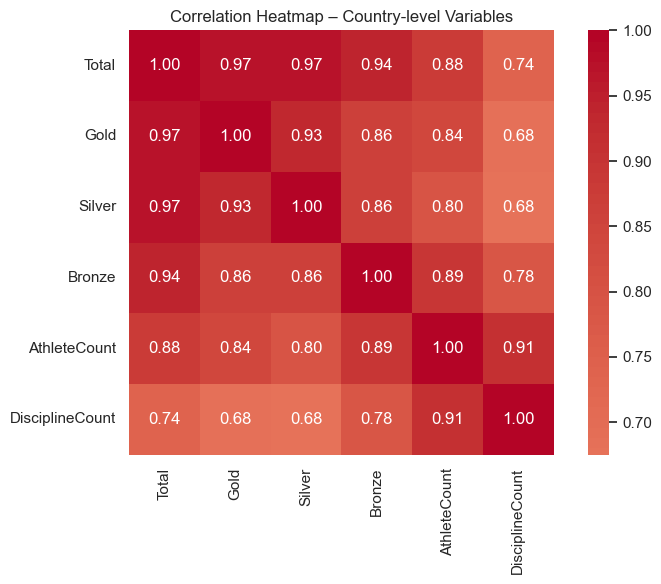

In [18]:
corr = df[['Total', 'Gold', 'Silver', 'Bronze', 'AthleteCount', 'DisciplineCount']].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Correlation Heatmap – Country-level Variables')
plt.tight_layout()
plt.show()

**Observation:** `AthleteCount` has a very strong positive correlation with `Total` medals (r = 0.88), and `DisciplineCount` also correlates strongly (r = 0.74). This gives us confidence that both variables are worth investigating with regression.

### Plot 4 – Scatterplot: Athlete Count vs Total Medals

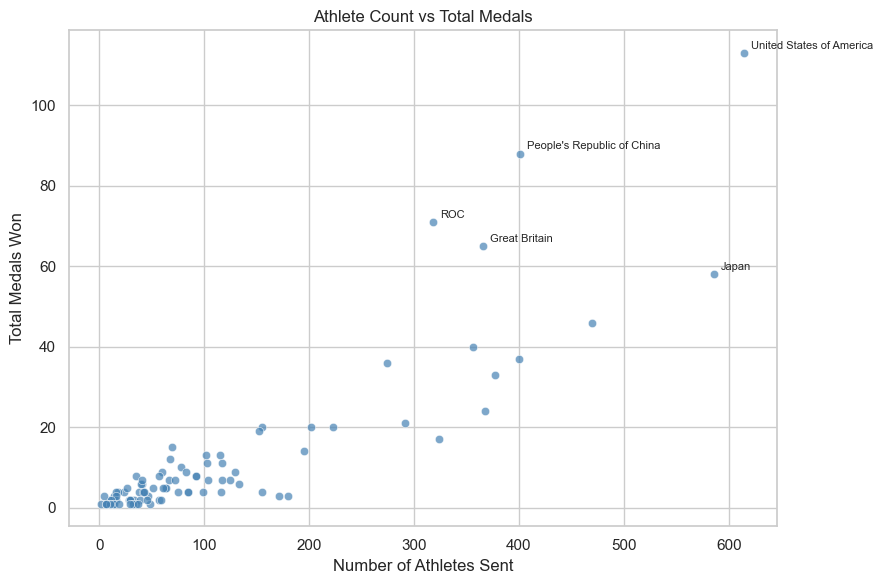

In [19]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='AthleteCount', y='Total', alpha=0.7, color='steelblue')

for _, row in df.nlargest(5, 'Total').iterrows():
    plt.annotate(row['Team/NOC'], (row['AthleteCount'], row['Total']),
                 textcoords='offset points', xytext=(5, 3), fontsize=8)

plt.title('Athlete Count vs Total Medals')
plt.xlabel('Number of Athletes Sent')
plt.ylabel('Total Medals Won')
plt.tight_layout()
plt.show()

**Observation:** There is a clear positive linear trend — countries that send more athletes tend to win more medals. The pattern appears roughly linear, supporting the use of simple linear regression.

### Plot 5 – Scatterplot: Discipline Count vs Total Medals

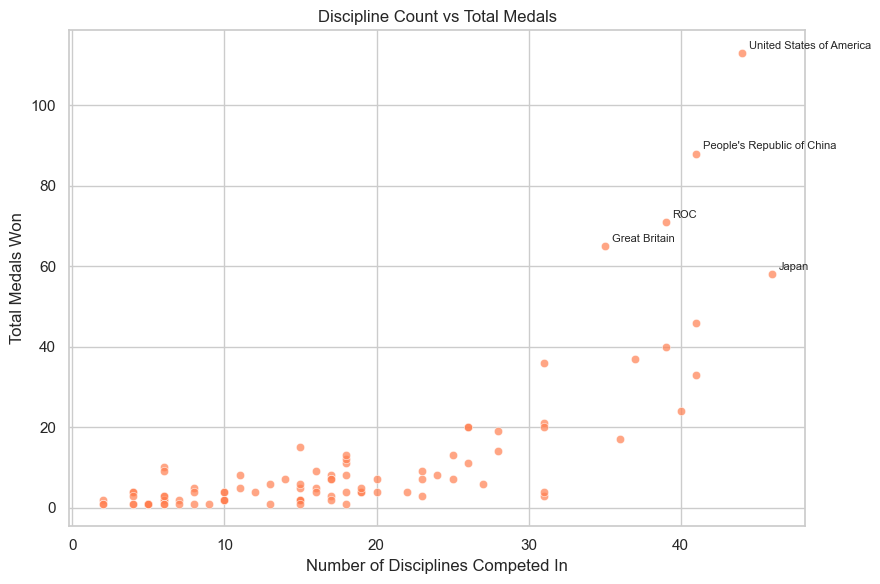

In [20]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='DisciplineCount', y='Total', alpha=0.7, color='coral')

for _, row in df.nlargest(5, 'Total').iterrows():
    plt.annotate(row['Team/NOC'], (row['DisciplineCount'], row['Total']),
                 textcoords='offset points', xytext=(5, 3), fontsize=8)

plt.title('Discipline Count vs Total Medals')
plt.xlabel('Number of Disciplines Competed In')
plt.ylabel('Total Medals Won')
plt.tight_layout()
plt.show()

**Observation:** A positive linear trend is also visible here — countries competing in more disciplines tend to win more medals. However, the spread around the trend line appears wider than in Plot 4, suggesting that discipline count is a weaker predictor than athlete count.

---
## D. Simple Linear Regression

We build one simple linear regression model per research question. For each model we:
1. Build and summarise the model
2. Interpret the results in business terms
3. Check all 5 regression assumptions
4. Visualise the regression line

The 5 assumptions we check are:
1. **Linearity** – the relationship between X and Y is linear
2. **Independence** – observations are independent of each other
3. **Normality of residuals** – residuals follow a normal distribution
4. **Homoscedasticity** – residuals have constant variance
5. **No multicollinearity** – not applicable for simple regression (only one X)

---

### Model 1 – Athlete Count → Total Medals
**Research Question:** Is there a linear relationship between how many athletes a country sends and how many medals it wins?  
**Y:** Total medals | **X:** AthleteCount

In [21]:
model1 = smf.ols('Total ~ AthleteCount', data=df).fit()
print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:                  Total   R-squared:                       0.766
Model:                            OLS   Adj. R-squared:                  0.763
Method:                 Least Squares   F-statistic:                     297.6
Date:                Sat, 13 Jun 2026   Prob (F-statistic):           1.96e-30
Time:                        09:36:36   Log-Likelihood:                -338.23
No. Observations:                  93   AIC:                             680.5
Df Residuals:                      91   BIC:                             685.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -2.3832      1.259     -1.892   

#### Business Interpretation – Model 1

- **R² = 0.766** — Athlete count explains **76.6%** of the variation in total medal count across countries. This is a strong result, meaning the size of a country's delegation is a very good predictor of how many medals it wins.
- **Coefficient = 0.1274** — For every additional athlete a country sends, we expect it to win approximately **0.13 more medals** on average. Put differently, sending 8 extra athletes is associated with roughly 1 additional medal.
- **Intercept = -2.38** — This has no practical meaning on its own (a country cannot send zero athletes), but it is needed for the mathematical formula.
- **p-value < 0.001** — The relationship is **statistically significant**. The probability of observing this result by chance is essentially zero.

**Business conclusion:** Larger delegations are strongly associated with more medals. This suggests that national Olympic committees that invest in sending more athletes are likely to see better medal outcomes. However, this does not mean sending more athletes *causes* more medals — wealthier countries can afford both.

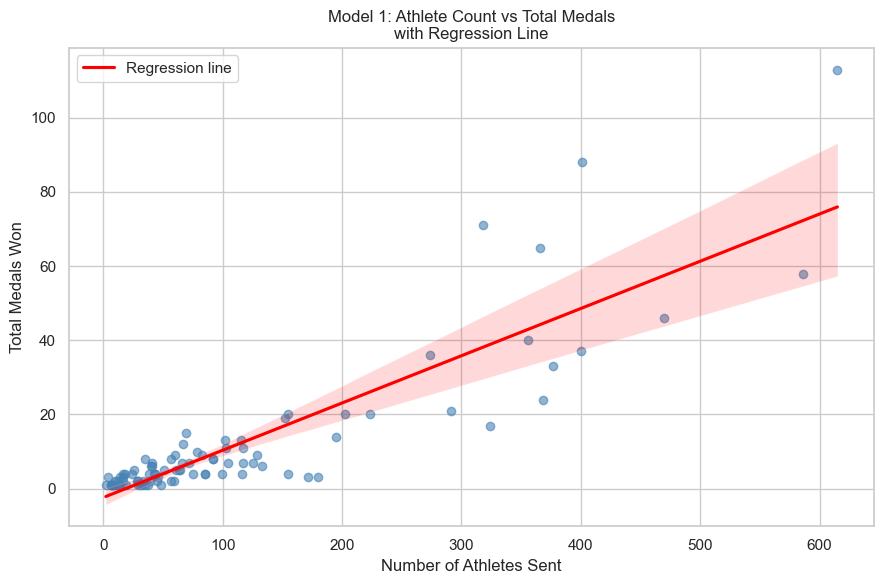

In [22]:
plt.figure(figsize=(9, 6))
sns.regplot(data=df, x='AthleteCount', y='Total',
            scatter_kws={'alpha': 0.6, 'color': 'steelblue'},
            line_kws={'color': 'red', 'label': 'Regression line'})
plt.title('Model 1: Athlete Count vs Total Medals\nwith Regression Line')
plt.xlabel('Number of Athletes Sent')
plt.ylabel('Total Medals Won')
plt.legend()
plt.tight_layout()
plt.show()

#### Assumption Checks – Model 1

**Assumption 1: Linearity**  
The scatterplot above shows a roughly linear pattern. We also inspect the residuals vs fitted values plot — if linearity holds, residuals should be randomly scattered around zero with no clear pattern.

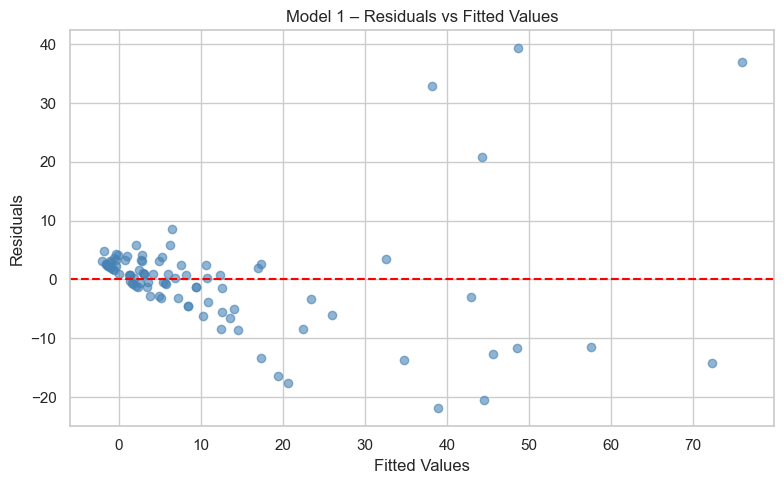

In [24]:
fitted1    = model1.fittedvalues
residuals1 = model1.resid

plt.figure(figsize=(8, 5))
plt.scatter(fitted1, residuals1, alpha=0.6, color='steelblue')
plt.axhline(0, color='red', linestyle='--')
plt.title('Model 1 – Residuals vs Fitted Values')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.tight_layout()
plt.show()

**Assumption 2: Independence**  
Each row represents a different country. Countries compete independently of one another, so this assumption is satisfied. ✅

**Assumption 3: Normality of Residuals**  
We check using a histogram, Q-Q plot, and the Shapiro-Wilk test (p > 0.05 = normality not rejected).

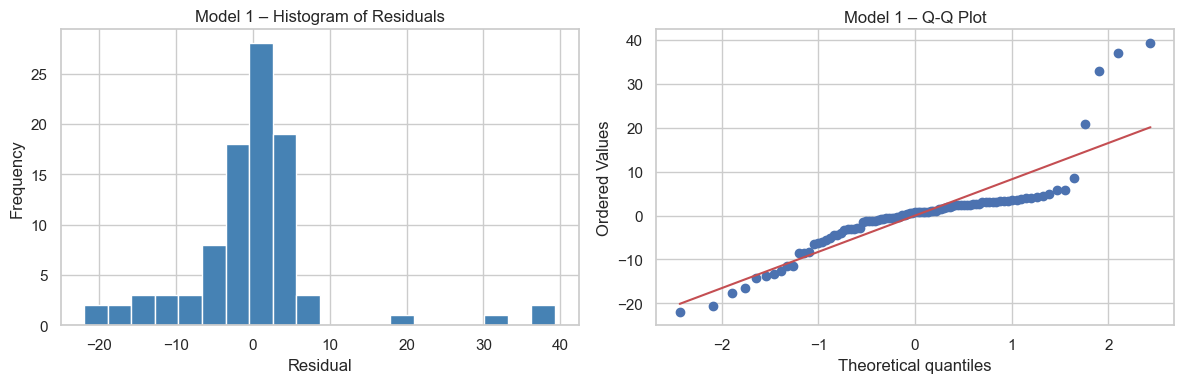

Shapiro-Wilk test: W=0.7848, p=0.0000
Result: Normality VIOLATED (p < 0.05) — residuals are not normally distributed


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(residuals1, bins=20, color='steelblue', edgecolor='white')
axes[0].set_title('Model 1 – Histogram of Residuals')
axes[0].set_xlabel('Residual')
axes[0].set_ylabel('Frequency')

stats.probplot(residuals1, dist='norm', plot=axes[1])
axes[1].set_title('Model 1 – Q-Q Plot')

plt.tight_layout()
plt.show()

sw1 = stats.shapiro(residuals1)
print(f'Shapiro-Wilk test: W={sw1.statistic:.4f}, p={sw1.pvalue:.4f}')
print('Result:', 'Normality SATISFIED (p > 0.05)' if sw1.pvalue > 0.05 else 'Normality VIOLATED (p < 0.05) — residuals are not normally distributed')

**Assumption 4: Homoscedasticity**  
Residuals should have constant variance across all fitted values (no funnel shape). We test with the Breusch-Pagan test (p > 0.05 = homoscedasticity satisfied).

In [26]:
bp1 = sms.het_breuschpagan(model1.resid, model1.model.exog)
print(f'Breusch-Pagan test: LM={bp1[0]:.4f}, p={bp1[1]:.4f}')
print('Result:', 'Homoscedasticity SATISFIED (p > 0.05)' if bp1[1] > 0.05 else 'Homoscedasticity VIOLATED (p < 0.05) — variance of residuals is not constant')

Breusch-Pagan test: LM=40.1783, p=0.0000
Result: Homoscedasticity VIOLATED (p < 0.05) — variance of residuals is not constant


**Assumption 5: No Multicollinearity**  
Not applicable for simple linear regression — we only have one independent variable. ✅

#### Assumption Summary – Model 1
| Assumption | Result | Notes |
|---|---|---|
| Linearity | ✅ | Roughly linear pattern in scatterplot and residuals plot |
| Independence | ✅ | Each country is an independent observation |
| Normality | ⚠️ | Violated — due to outliers (USA, China). Results should be interpreted with caution |
| Homoscedasticity | ⚠️ | Violated — larger delegations show more variance in residuals |
| Multicollinearity | ✅ | N/A for simple regression |

**Note:** The violations are largely driven by the extreme outliers (USA, China, ROC). Despite these violations, the model is still informative and the strong R² and significant p-value give us confidence in the general trend. We discuss this further in the limitations section.

---

### Model 2 – Discipline Count → Total Medals
**Research Question:** Do countries that compete in more disciplines tend to win more medals?  
**Y:** Total medals | **X:** DisciplineCount

In [27]:
model2 = smf.ols('Total ~ DisciplineCount', data=df).fit()
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                  Total   R-squared:                       0.549
Model:                            OLS   Adj. R-squared:                  0.544
Method:                 Least Squares   F-statistic:                     110.7
Date:                Sat, 13 Jun 2026   Prob (F-statistic):           2.09e-17
Time:                        09:47:00   Log-Likelihood:                -368.73
No. Observations:                  93   AIC:                             741.5
Df Residuals:                      91   BIC:                             746.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept         -10.2319      2.469     

#### Business Interpretation – Model 2

- **R² = 0.549** — The number of disciplines a country competes in explains **54.9%** of the variation in total medal count. This is a moderate-to-strong result, though noticeably weaker than Model 1 (76.6%).
- **Coefficient = 1.244** — For every additional discipline a country competes in, we expect it to win approximately **1.24 more medals** on average.
- **Intercept = -10.23** — Again, this has no direct practical meaning as a country cannot compete in zero disciplines.
- **p-value < 0.001** — The relationship is **statistically significant**.

**Business conclusion:** Countries that spread their athletes across more sports tend to win more medals. This could suggest that building strength across a broad range of disciplines is associated with Olympic success. However, it is important to note that bigger delegations naturally compete in more disciplines — the two variables are related. Model 1 remains a stronger predictor.

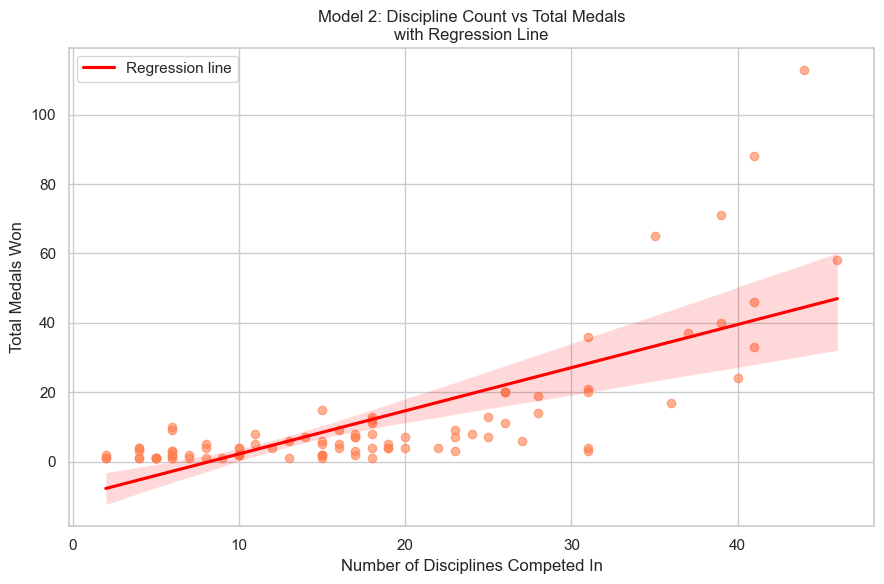

In [28]:
plt.figure(figsize=(9, 6))
sns.regplot(data=df, x='DisciplineCount', y='Total',
            scatter_kws={'alpha': 0.6, 'color': 'coral'},
            line_kws={'color': 'red', 'label': 'Regression line'})
plt.title('Model 2: Discipline Count vs Total Medals\nwith Regression Line')
plt.xlabel('Number of Disciplines Competed In')
plt.ylabel('Total Medals Won')
plt.legend()
plt.tight_layout()
plt.show()

#### Assumption Checks – Model 2

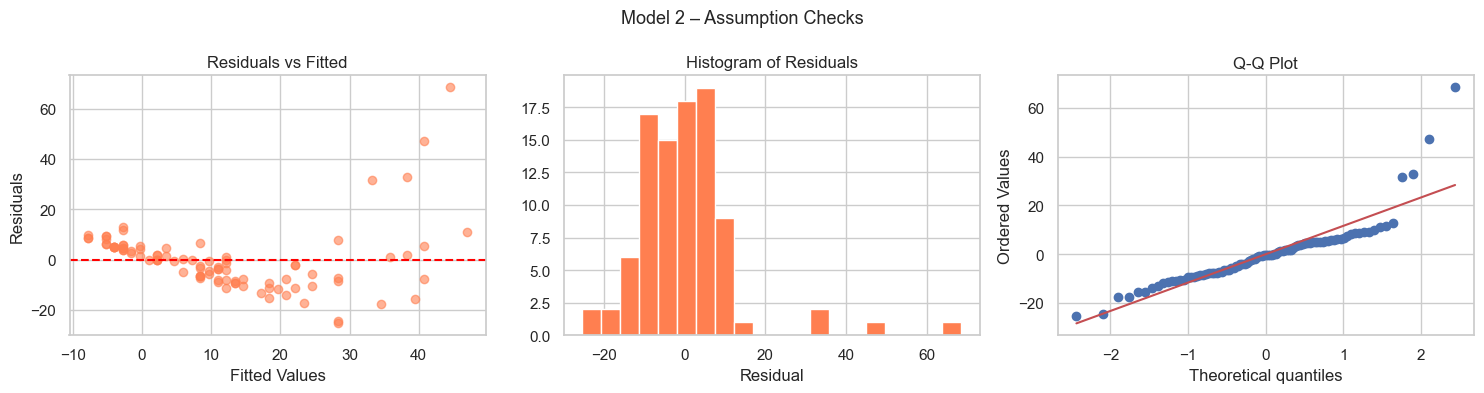

Shapiro-Wilk:  p=0.0000 → VIOLATED
Breusch-Pagan: p=0.0000 → VIOLATED


In [29]:
fitted2    = model2.fittedvalues
residuals2 = model2.resid

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Residuals vs Fitted
axes[0].scatter(fitted2, residuals2, alpha=0.6, color='coral')
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title('Residuals vs Fitted')
axes[0].set_xlabel('Fitted Values')
axes[0].set_ylabel('Residuals')

# Histogram
axes[1].hist(residuals2, bins=20, color='coral', edgecolor='white')
axes[1].set_title('Histogram of Residuals')
axes[1].set_xlabel('Residual')

# Q-Q plot
stats.probplot(residuals2, dist='norm', plot=axes[2])
axes[2].set_title('Q-Q Plot')

plt.suptitle('Model 2 – Assumption Checks', fontsize=13)
plt.tight_layout()
plt.show()

sw2 = stats.shapiro(residuals2)
bp2 = sms.het_breuschpagan(model2.resid, model2.model.exog)
print(f'Shapiro-Wilk:  p={sw2.pvalue:.4f} → {"SATISFIED" if sw2.pvalue > 0.05 else "VIOLATED"}')
print(f'Breusch-Pagan: p={bp2[1]:.4f} → {"SATISFIED" if bp2[1] > 0.05 else "VIOLATED"}')

#### Assumption Summary – Model 2
| Assumption | Result | Notes |
|---|---|---|
| Linearity | ✅ | Positive linear trend visible in scatterplot |
| Independence | ✅ | Each country is an independent observation |
| Normality | ⚠️ | Violated — same outlier effect as Model 1 |
| Homoscedasticity | ⚠️ | Violated — variance increases for countries with more disciplines |
| Multicollinearity | ✅ | N/A for simple regression |

---
## F. Model Comparison & Insights

In [30]:
comparison = pd.DataFrame({
    'Model': [
        'Model 1: AthleteCount → Total Medals',
        'Model 2: DisciplineCount → Total Medals'
    ],
    'R²': [round(model1.rsquared, 3), round(model2.rsquared, 3)],
    'Coefficient (X)': [
        round(model1.params['AthleteCount'], 4),
        round(model2.params['DisciplineCount'], 4)
    ],
    'p-value': [
        round(model1.pvalues['AthleteCount'], 4),
        round(model2.pvalues['DisciplineCount'], 4)
    ],
    'Significant': ['Yes', 'Yes']
})

display(comparison)

,Model,R²,Coefficient (X),p-value,Significant
0,Model 1: AthleteCount → Total Medals,0.766,0.1274,0.0,Yes
1,Model 2: DisciplineCount → Total Medals,0.549,1.2441,0.0,Yes


**Key Findings:**

- Both models show a **statistically significant positive relationship** with total medal count (p < 0.001 in both cases).
- **Model 1 (AthleteCount) is the stronger predictor** with R² = 0.766, compared to Model 2 (R² = 0.549). Squad size explains about 27 percentage points more variance than discipline count.
- This suggests that **how many athletes you send matters more than how many different sports you compete in**, when predicting medal outcomes.
- It is worth noting that the two predictors are themselves correlated — countries that send more athletes naturally compete in more disciplines. This means Model 2 may partly be capturing the same effect as Model 1.

**Business Recommendation:**  
For national Olympic committees with limited budgets, the data suggests that **investing in growing the overall athlete pool** is more strongly associated with medal success than spreading resources thinly across many disciplines. Focusing on depth in fewer sports may be a more effective strategy for smaller nations.

---
## G. Limitations & Conclusions

### Conclusions
1. There is a **strong positive linear association** between the number of athletes a country sends and its total medal count (R² = 0.766). Larger delegations are consistently associated with more medals.
2. There is a **moderate positive association** between competing in more disciplines and winning more medals (R² = 0.549). However, this is partly explained by the fact that bigger delegations naturally compete in more sports.
3. **Athlete count is the stronger predictor** of the two, making squad size the most informative variable in this dataset for explaining medal outcomes.

### Limitations
1. **Correlation ≠ Causation:** Sending more athletes does not *cause* more medals. Wealthier and more populous countries can afford both larger delegations *and* better training facilities, coaching, and sports infrastructure. The relationship is likely driven by a third factor: national sporting investment.
2. **Assumption violations:** Both models violate the normality and homoscedasticity assumptions, largely due to outlier countries (USA, China, ROC). This means confidence intervals and p-values should be interpreted with some caution, though the overall trends remain clear.
3. **Outliers:** The USA and China have an outsized influence on the regression lines. Running models without these countries would be an interesting sensitivity check.
4. **Missing variables:** The dataset does not include GDP, population size, sports budget, or historical Olympic performance — all of which would likely improve the models significantly.
5. **Single edition:** This analysis covers only Tokyo 2020. Results may differ for other Olympic Games.

### Suggestions for Future Analysis
- Enrich the dataset with GDP or population data to control for country size
- Compare multiple Olympic Games editions to identify performance trends over time
- Investigate whether the relationship holds within specific regions or income groups